# Who actually supplies this brand? Reproducing the corrected call list

**Research lead:** Joash Boyton, Acquiry Labs. **Source:** [Research edition 1.1](https://www.acquiry.com/labs/who-supplies-this-brand/editions/1.1/) (13 November 2026). Teaching kit 1.1.

A shared checkout makes ten shops *look* like customers of one supplier. Count only shops with independent evidence and the supplier keeps three supported relationships. That changes which acquisition target a buyer should call first.

The two ranking scenarios below use **fictional** shops and suppliers from the public teaching kit. The real-world opening example in the research edition is Squarespace and Stripe. The separately versioned companion dataset is the [Embedded Payments Provider Map, dataset edition 1.1](https://www.acquiry.com/data/embedded-payments-provider-map/editions/1.1/).

Licence: CC BY 4.0. Credit: Joash Boyton, Acquiry Labs.

## The rule

1. A shop counts for a supplier only with **independent evidence** (here, an independent platform record).
2. The shared checkout is **not** independent evidence.
3. Rank suppliers by supported shops, then by name A to Z.

In [1]:
import json
from pathlib import Path

KIT = next((p for p in [Path("kit"), *Path("/kaggle/input").glob("*/kit")] if p.is_dir()), Path("kit"))  # local clone or Kaggle dataset

def load(letter):
    case = json.loads((KIT / f"retail-input-{letter}.json").read_text())
    expected = json.loads((KIT / f"expected-output-{letter}.json").read_text())
    return case, expected

def rank(case):
    visible = {s["id"] for s in case["shops"] if s["shared_checkout"]}
    supported = {s["id"] for s in case["shops"] if s["independent_platform_record"]}
    def order(arc_count):
        counts = {**case["other_supplier_counts"], "Arc": arc_count}
        return sorted(counts, key=lambda s: (-counts[s], s)), counts
    before, before_counts = order(len(visible | supported))
    after, after_counts = order(len(supported))
    return before, before_counts, after, after_counts, supported

print("Loaded kit from", KIT.resolve().name)

Loaded kit from kit


In [2]:
for letter in ("a", "b"):
    case, expected = load(letter)
    before, bc, after, ac, supported = rank(case)
    print(f"Scenario {letter.upper()}: {case['scenario']}")
    print("  Arc shops: visible", bc["Arc"], "-> supported", len(supported))
    print("  Call list BEFORE correction:", " > ".join(f"{s} ({bc[s]})" for s in before[:3]))
    print("  Call list AFTER correction: ", " > ".join(f"{s} ({ac[s]})" for s in after[:3]))
    assert before[:3] == expected["before"] and after[:3] == expected["after"], "mismatch with expected output"
    print("  Matches expected-output-" + letter + ".json")
    print()

Scenario A: Synthetic retail teaching case, Scenario A (fictional)
  Arc shops: visible 10 -> supported 3
  Call list BEFORE correction: Arc (10) > Birch (8) > Cove (6)
  Call list AFTER correction:  Birch (8) > Cove (6) > Dune (4)
  Matches expected-output-a.json

Scenario B: Synthetic retail teaching case, Scenario B, alternative fictional scenario (fictional)
  Arc shops: visible 10 -> supported 3
  Call list BEFORE correction: Arc (10) > Birch (8) > Cove (6)
  Call list AFTER correction:  Birch (8) > Cove (6) > Arc (3)
  Matches expected-output-b.json



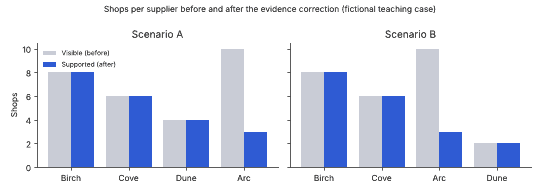

In [3]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, letter in zip(axes, ("a", "b")):
    case, _ = load(letter)
    before, bc, after, ac, _ = rank(case)
    names = sorted(bc, key=lambda s: (-ac[s], s))
    x = range(len(names))
    ax.bar([i - 0.2 for i in x], [bc[n] for n in names], width=0.4, label="Visible (before)", color="#c9ccd6")
    ax.bar([i + 0.2 for i in x], [ac[n] for n in names], width=0.4, label="Supported (after)", color="#2f5bd3")
    ax.set_xticks(list(x)); ax.set_xticklabels(names)
    ax.set_title(f"Scenario {letter.upper()}")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Shops")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Shops per supplier before and after the evidence correction (fictional teaching case)", fontsize=10)
fig.tight_layout()
plt.show()

## What changed

- **Scenario A:** Arc drops from first to off the shortlist. Dune enters as the third call.
- **Scenario B:** the same three suppliers stay on the shortlist, but Arc falls from first to third.

Either way, a buyer working from the visible integration would have called the wrong company first.

Read the full method, the evidence-to-decision grouping and the review of all ten dataset rows in [research edition 1.1](https://www.acquiry.com/labs/who-supplies-this-brand/editions/1.1/).

*Cite as:* Acquiry Labs. *Who actually supplies this brand?* Research lead Joash Boyton. Research edition 1.1, 13 November 2026. https://www.acquiry.com/labs/who-supplies-this-brand/editions/1.1/